# ทำนายระดับความเสี่ยงโรคอ้วนจากพฤติกรรมการกินและการออกกำลังกาย

- ข้อมูล: UCI Obesity Levels Dataset (`aravindpcoder/obesity-or-cvd-risk-classifyregressorcluster`)
- เป้าหมาย: แบ่งความเสี่ยง 3 ระดับ (`Low`, `Medium`, `High`) โดยไม่ใช้ `Weight` และ `Height` เพื่อกัน Data Leakage จากค่า BMI
- ตัวชี้วัด: 5-Fold CV Macro-F1, Test Macro-F1, Accuracy

In [1]:
# !pip install -q kagglehub lightgbm scikit-learn matplotlib seaborn

In [2]:
import glob
import os
import warnings

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 1. โหลดข้อมูลและเตรียม Feature

In [3]:
path = kagglehub.dataset_download("aravindpcoder/obesity-or-cvd-risk-classifyregressorcluster")
csv_path = glob.glob(os.path.join(path, "**/*.csv"), recursive=True)[0]

df = pd.read_csv(csv_path)
print("raw:", df.shape, "| missing:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))

df = df.drop_duplicates().copy()

def to_risk_level(label):
    if "Obesity" in str(label):
        return "High"
    if "Overweight" in str(label):
        return "Medium"
    return "Low"

class_names = ["Low", "Medium", "High"]
label_map = {name: i for i, name in enumerate(class_names)}
df["Risk_Level"] = df["NObeyesdad"].apply(to_risk_level)

print(df["Risk_Level"].value_counts().reindex(class_names))

Using Colab cache for faster access to the 'obesity-or-cvd-risk-classifyregressorcluster' dataset.
raw: (2111, 17) | missing: 0 | duplicates: 24
Risk_Level
Low       549
Medium    566
High      972
Name: count, dtype: int64


In [4]:
base_cols = [
    "Gender", "Age", "family_history_with_overweight", "FAVC", "FCVC",
    "NCP", "CAEC", "SMOKE", "CH2O", "SCC", "FAF", "TUE", "CALC", "MTRANS",
]

X = df[base_cols].copy()
y = df["Risk_Level"].map(label_map)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (1669, 14) | test: (418, 14)


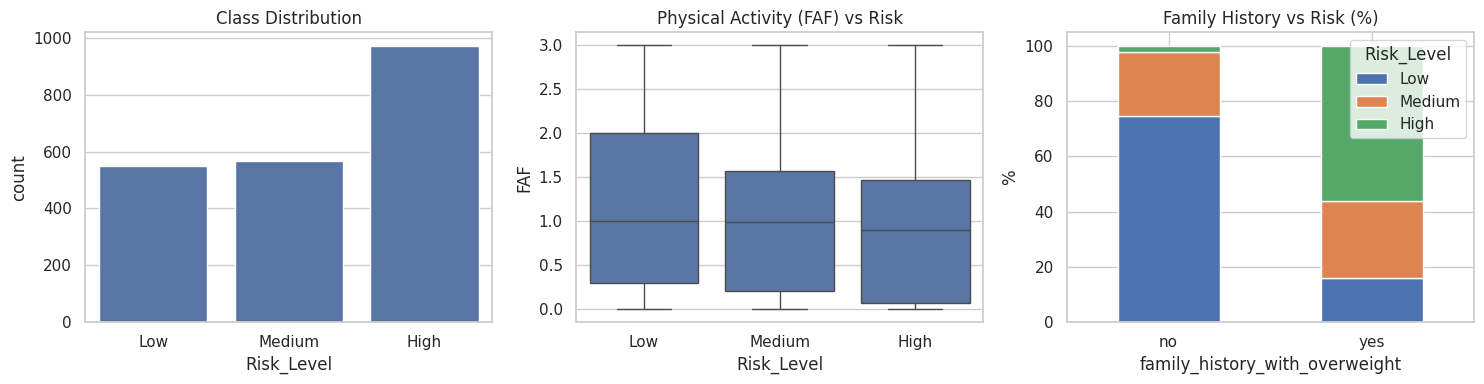

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x="Risk_Level", order=class_names, ax=axes[0])
axes[0].set_title("Class Distribution")

sns.boxplot(data=df, x="Risk_Level", y="FAF", order=class_names, ax=axes[1])
axes[1].set_title("Physical Activity (FAF) vs Risk")

ct = pd.crosstab(df["family_history_with_overweight"], df["Risk_Level"], normalize="index")[class_names] * 100
ct.plot(kind="bar", stacked=True, ax=axes[2])
axes[2].set_title("Family History vs Risk (%)")
axes[2].set_ylabel("%")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 2. เปรียบเทียบโมเดลและวัดผล

In [6]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

models = {
    "Baseline (Majority)": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression": LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced", random_state=42),
    "RandomForest": RandomForestClassifier(
        n_estimators=250, max_depth=10, min_samples_leaf=3,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=250, learning_rate=0.05, max_depth=6, num_leaves=23,
        min_child_samples=15, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.5, reg_lambda=2.0, class_weight="balanced",
        random_state=42, verbose=-1, n_jobs=-1
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
fitted = {}
test_preds = {}
per_class_f1 = {}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    pipe.fit(X_train, y_train)

    pred_tr = pipe.predict(X_train)
    pred_te = pipe.predict(X_test)
    fitted[name] = pipe
    test_preds[name] = pred_te
    per_class_f1[name] = f1_score(y_test, pred_te, average=None)

    rows.append({
        "Model": name,
        "Train F1": round(f1_score(y_train, pred_tr, average="macro"), 4),
        "CV F1": round(cv_f1, 4),
        "Test F1": round(f1_score(y_test, pred_te, average="macro"), 4),
        "Test Acc": round(accuracy_score(y_test, pred_te), 4),
    })

results_df = pd.DataFrame(rows)
baseline_f1 = results_df.loc[results_df["Model"] == "Baseline (Majority)", "Test F1"].iloc[0]
results_df["Δ F1 vs Baseline"] = (results_df["Test F1"] - baseline_f1).round(4)
print(results_df.to_string(index=False))

best_name = results_df[results_df["Model"] != "Baseline (Majority)"].sort_values("Test F1", ascending=False).iloc[0]["Model"]
best_pipe = fitted[best_name]
best_pred = test_preds[best_name]

print(f"\nClassification Report ({best_name})")
print(classification_report(y_test, best_pred, target_names=class_names))

              Model  Train F1  CV F1  Test F1  Test Acc  Δ F1 vs Baseline
Baseline (Majority)    0.2118 0.2118   0.2121    0.4665            0.0000
 LogisticRegression    0.6788 0.6633   0.6681    0.6818            0.4560
       RandomForest    0.9162 0.8259   0.8469    0.8565            0.6348
           LightGBM    0.9795 0.8337   0.8568    0.8660            0.6447

Classification Report (LightGBM)
              precision    recall  f1-score   support

         Low       0.86      0.85      0.85       110
      Medium       0.79      0.83      0.81       113
        High       0.92      0.90      0.91       195

    accuracy                           0.87       418
   macro avg       0.86      0.86      0.86       418
weighted avg       0.87      0.87      0.87       418



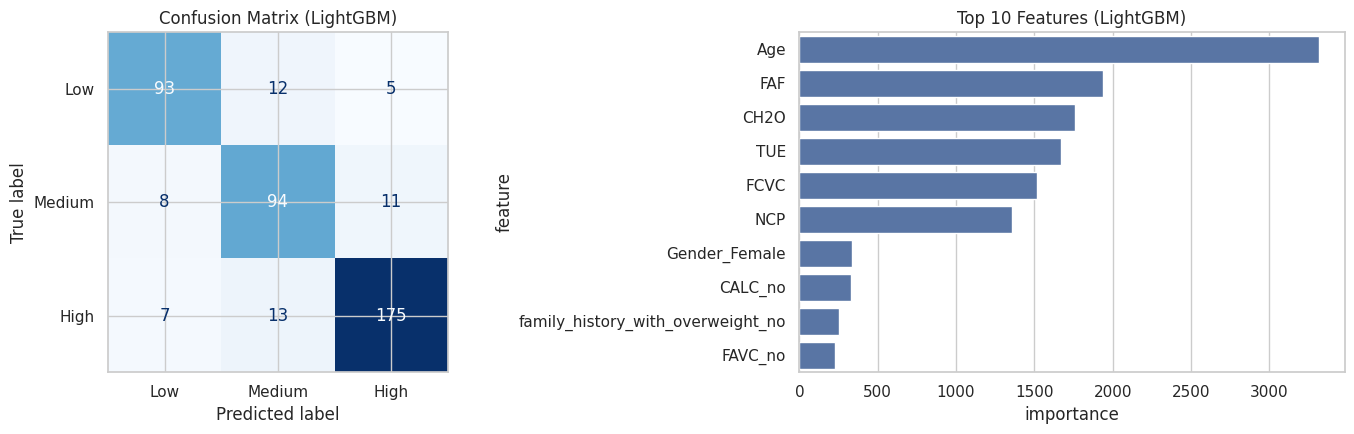

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=class_names, cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title(f"Confusion Matrix ({best_name})")

prep = best_pipe.named_steps["prep"]
model = best_pipe.named_steps["model"]
feat_names = [f.replace("num__", "").replace("cat__", "") for f in prep.get_feature_names_out()]
imp = model.feature_importances_ if hasattr(model, "feature_importances_") else np.mean(np.abs(model.coef_), axis=0)

top_feat = pd.DataFrame({"feature": feat_names, "importance": imp}).sort_values("importance", ascending=False).head(10)
sns.barplot(data=top_feat, x="importance", y="feature", ax=axes[1])
axes[1].set_title(f"Top 10 Features ({best_name})")

plt.tight_layout()
plt.show()

In [8]:
# ดูตัวอย่างเคสที่ทายผิด
err = X_test.copy()
err["actual"] = [class_names[i] for i in y_test]
err["pred"] = [class_names[i] for i in best_pred]
mis = err[err["actual"] != err["pred"]]

print(f"misclassified: {len(mis)} / {len(err)} ({len(mis)/len(err)*100:.1f}%)")
print(mis[["actual", "pred", "Age", "family_history_with_overweight", "FAVC", "FCVC", "FAF", "TUE", "CAEC"]].head(5).to_string())

misclassified: 56 / 418 (13.4%)
      actual    pred        Age family_history_with_overweight FAVC      FCVC       FAF       TUE        CAEC
407   Medium     Low  19.000000                            yes  yes  3.000000  1.000000  2.000000  Frequently
1424    High  Medium  36.679330                            yes  yes  2.540949  2.787319  0.732881   Sometimes
1543    High  Medium  21.556361                            yes  yes  2.000000  1.399183  1.000000   Sometimes
815   Medium    High  21.086512                            yes  yes  2.000000  0.000000  0.798219   Sometimes
1340    High  Medium  21.980847                            yes  yes  2.000000  0.000000  0.808980   Sometimes


**4. Extension (Model 2): Personalized Lifestyle Recommendations**

In [11]:
# 4.1 Rule engine: สร้างตัวอย่างคำแนะนำเพื่อใช้เป็น Target Label ของ ML2

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier

REC_LABELS = [
    "Nutrition Support",
    "Improve Diet",
    "Increase Activity",
    "Improve Lifestyle",
    "Maintain Habits",
]

REC_THAI = {
    "Nutrition Support": "ทบทวนโภชนาการให้ได้รับอาหารและพลังงานเพียงพอ",
    "Improve Diet": "ปรับคุณภาพและความสมดุลของอาหาร",
    "Increase Activity": "ค่อย ๆ เพิ่มกิจกรรมทางกาย",
    "Improve Lifestyle": "ทบทวนพฤติกรรมประจำวันเพื่อสุขภาพ",
    "Maintain Habits": "รักษาพฤติกรรมที่เหมาะสมและติดตามสุขภาพ",
}


def generate_rule_label(row):
    bmi = float(row["BMI"])
    age = float(row["Age"])
    if not np.isfinite(bmi) or bmi <= 0 or age < 20:
        raise ValueError("ML2 Demo รองรับเฉพาะผู้ใหญ่อายุ 20 ปีขึ้นไปที่มี BMI ใช้งานได้")

    score = {k: 0.0 for k in REC_LABELS if k != "Maintain Habits"}
    reasons = []
    underweight = bmi < 18.5
    overweight = bmi >= 25.0

    # BMI - จุดตั้งต้นสำหรับเลือกเป้าหมายที่เหมาะกับบริบทน้ำหนัก
    if underweight:
        score["Nutrition Support"] += 12
        reasons.append("BMI ต่ำกว่า 18.5: เน้นโภชนาการที่เพียงพอ ไม่แนะนำการจำกัดอาหาร")
    elif overweight:
        score["Improve Diet"] += 1.5
        reasons.append("BMI ตั้งแต่ 25: ทบทวนพฤติกรรมอาหารและกิจกรรม (ไม่ใช่การวินิจฉัย)")
    else:
        reasons.append("BMI อยู่ในช่วง 18.5–24.9")

    # Activity: FAF, TUE, MTRANS
    if float(row["FAF"]) < 0.75:
        score["Increase Activity"] += 5
        reasons.append("FAF ต่ำมาก: มีกิจกรรมทางกายค่อนข้างน้อย")
    elif float(row["FAF"]) < 1.5:
        score["Increase Activity"] += 2
        reasons.append("FAF ค่อนข้างต่ำ")

    if float(row["TUE"]) >= 1.5:
        score["Increase Activity"] += 1
        reasons.append("TUE สูง: เวลาที่ใช้อุปกรณ์เทคโนโลยีค่อนข้างมาก")

    if str(row["MTRANS"]) in ("Automobile", "Motorbike"):
        score["Increase Activity"] += 1
        reasons.append("การเดินทางหลักเป็นยานพาหนะ: พิจารณาเพิ่มการเคลื่อนไหวระหว่างวัน")

    if overweight and float(row["FAF"]) < 1.5:
        score["Increase Activity"] += 2

    # Diet: FAVC, FCVC, NCP, CAEC
    if str(row["FAVC"]).lower() == "yes":
        score["Improve Diet"] += 2.5
        reasons.append("FAVC=yes: รายงานว่ากินอาหารพลังงานสูงบ่อย")

    if float(row["FCVC"]) < 1.8:
        score["Improve Diet"] += 2
        reasons.append("FCVC ต่ำ: ความถี่การกินผักค่อนข้างน้อย")

    if str(row["CAEC"]) in ("Frequently", "Always"):
        score["Improve Diet"] += 1
        reasons.append("CAEC บ่อย: ควรทบทวนชนิดและปริมาณอาหารระหว่างมื้อ")

    if float(row["NCP"]) < 1.6:
        if underweight:
            score["Nutrition Support"] += 2
        else:
            score["Improve Diet"] += 0.5
        reasons.append("NCP ต่ำ: ลองทบทวนความเพียงพอและความสม่ำเสมอของมื้ออาหาร")

    # Lifestyle: CH2O, SMOKE, CALC
    if float(row["CH2O"]) < 1.5:
        score["Improve Lifestyle"] += 2
        reasons.append("CH2O ต่ำ: ทบทวนความเพียงพอของน้ำดื่ม")

    if str(row["SMOKE"]).lower() == "yes":
        score["Improve Lifestyle"] += 4
        reasons.append("SMOKE=yes: ควรได้รับข้อมูลและความช่วยเหลือเรื่องการเลิกสูบ")

    if str(row["CALC"]) in ("Frequently", "Always"):
        score["Improve Lifestyle"] += 3
        reasons.append("CALC บ่อย: พิจารณาลด/งดแอลกอฮอล์")

    # ML1 predicted result: ให้โมเดลแรกประกอบ
    risk = str(row["ML1_Predicted_Risk"])
    if risk == "High" and overweight:
        if float(row["FAF"]) < 1.5:
            score["Increase Activity"] += 1
        if str(row["FAVC"]).lower() == "yes":
            score["Improve Diet"] += 1

    # Unmodifiable/contextual inputs are considered without assigning 'behavior blame'
    # Gender: not used to determine the behavior to change
    # family_history_with_overweight: context for follow-up, never a standalone action label
    # SCC: no assumption that calorie counting is universally necessary
    if str(row["family_history_with_overweight"]).lower() == "yes":
        reasons.append("มีประวัติครอบครัว: เป็นข้อมูลประกอบ ไม่ใช่พฤติกรรมที่ต้องแก้")
    if str(row["SCC"]).lower() == "no":
        reasons.append("ไม่ติดตามแคลอรี: ไม่ถือว่าเป็นพฤติกรรมผิดโดยตัวมันเอง")
    if age >= 60:
        reasons.append("อายุ 60 ปีขึ้นไป: ควรพิจารณากิจกรรมให้เหมาะกับความสามารถ")

    # Underweight takes priority in this educational teacher (nutrition adequacy first)
    # For other cases, pick the highest-scoring behavioral priority
    if underweight:
        label = "Nutrition Support"
    elif max(score.values()) < 2:
        label = "Maintain Habits"
    else:
        # Stable tie order for deterministic labels
        priority = ["Increase Activity", "Improve Diet", "Improve Lifestyle", "Nutrition Support"]
        label = max(priority, key=lambda name: score[name])

    return label, "; ".join(reasons), score


In [12]:
# 4.2 สร้าง Label ด้วยข้อมูลจาก df ที่โหลดไว้
# คำนวณ Label ให้ทุกแถวจริงใน df
# แยก train/test ตาม X_train, X_test เดิม เพื่อไม่เอาแถวของ test ไปฝึก ML2
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

assert {"Age", "Height", "Weight"}.issubset(df.columns)
rec_df = df.loc[(df["Age"] >= 20) & (df["Height"] > 0) & (df["Weight"] > 0)].copy()
rec_df["BMI"] = rec_df["Weight"] / rec_df["Height"].pow(2)
rec_df = rec_df.loc[np.isfinite(rec_df["BMI"])].copy()

# Cross-validated (out-of-fold) prediction for ML1 training rows reduces in-sample optimism
cv1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ml1_oof = cross_val_predict(clone(best_pipe), X_train[base_cols], y_train, cv=cv1)
ml1_train_pred = pd.Series([class_names[int(v)] for v in ml1_oof], index=X_train.index)
ml1_test_pred = pd.Series([class_names[int(v)] for v in best_pipe.predict(X_test[base_cols])], index=X_test.index)
rec_df["ML1_Predicted_Risk"] = pd.concat([ml1_train_pred, ml1_test_pred]).reindex(rec_df.index)
assert rec_df["ML1_Predicted_Risk"].notna().all(), "Risk predictions are missing"

# Generate teacher targets (not expert-validated labels)
rule_res = [generate_rule_label(r) for _, r in rec_df.iterrows()]
rec_df["Recommendation_Label"] = [r[0] for r in rule_res]
rec_df["Rule_Explanation"] = [r[1] for r in rule_res]

ML2_FEATURES = base_cols + ["BMI", "ML1_Predicted_Risk"]
idx_train = X_train.index.intersection(rec_df.index)
idx_test = X_test.index.intersection(rec_df.index)
X2_train = rec_df.loc[idx_train, ML2_FEATURES].copy()
X2_test = rec_df.loc[idx_test, ML2_FEATURES].copy()
y2_train = rec_df.loc[idx_train, "Recommendation_Label"]
y2_test = rec_df.loc[idx_test, "Recommendation_Label"]

print("ML2 records:", len(rec_df), "| Train:", len(X2_train), "| Test:", len(X2_test))
print("\nRecommendation Label counts (from teacher rules):")
print(rec_df["Recommendation_Label"].value_counts().reindex(REC_LABELS, fill_value=0))
print("\nActual dataset examples after rule-generated labeling:")
display(
    rec_df[
        [
            "Age", "Height", "Weight", "BMI",
            "FAF", "FAVC", "FCVC", "CH2O",
            "ML1_Predicted_Risk",
            "Recommendation_Label",
            "Rule_Explanation"
        ]
    ].head(15).round(2)
)

rec_df.to_csv("recommendation_rule_labeled_dataset.csv", index=False, encoding="utf-8-sig")
print("Export ready: recommendation_rule_labeled_dataset.csv")


ML2 records: 1553 | Train: 1242 | Test: 311

Recommendation Label counts (from teacher rules):
Recommendation_Label
Nutrition Support     91
Improve Diet         414
Increase Activity    978
Improve Lifestyle     39
Maintain Habits       31
Name: count, dtype: int64

Actual dataset examples after rule-generated labeling:


,Age,Height,Weight,BMI,FAF,FAVC,FCVC,CH2O,ML1_Predicted_Risk,Recommendation_Label,Rule_Explanation
0,21.0,1.62,64.0,24.39,0.0,no,2.0,2.0,Medium,Increase Activity,BMI อยู่ในช่วง 18.5–24.9; FAF ต่ำมาก: มีกิจกรร...
1,21.0,1.52,56.0,24.24,3.0,no,3.0,3.0,Medium,Improve Lifestyle,BMI อยู่ในช่วง 18.5–24.9; SMOKE=yes: ควรได้รับ...
2,23.0,1.80,77.0,23.77,2.0,no,2.0,2.0,Low,Improve Lifestyle,BMI อยู่ในช่วง 18.5–24.9; CALC บ่อย: พิจารณาลด...
3,27.0,1.80,87.0,26.85,2.0,no,3.0,2.0,Medium,Improve Lifestyle,BMI ตั้งแต่ 25: ทบทวนพฤติกรรมอาหารและกิจกรรม (...
4,22.0,1.78,89.8,28.34,0.0,no,2.0,2.0,Low,Increase Activity,BMI ตั้งแต่ 25: ทบทวนพฤติกรรมอาหารและกิจกรรม (...
5,29.0,1.62,53.0,20.20,0.0,yes,2.0,2.0,Medium,Increase Activity,BMI อยู่ในช่วง 18.5–24.9; FAF ต่ำมาก: มีกิจกรร...
6,23.0,1.50,55.0,24.44,1.0,yes,3.0,2.0,Low,Increase Activity,BMI อยู่ในช่วง 18.5–24.9; FAF ค่อนข้างต่ำ; การ...
7,22.0,1.64,53.0,19.71,3.0,no,2.0,2.0,Low,Maintain Habits,BMI อยู่ในช่วง 18.5–24.9; ไม่ติดตามแคลอรี: ไม่...
8,24.0,1.78,64.0,20.20,1.0,yes,3.0,2.0,Medium,Improve Lifestyle,BMI อยู่ในช่วง 18.5–24.9; FAF ค่อนข้างต่ำ; FAV...
9,22.0,1.72,68.0,22.99,1.0,yes,2.0,2.0,Low,Improve Diet,BMI อยู่ในช่วง 18.5–24.9; FAF ค่อนข้างต่ำ; FAV...


Export ready: recommendation_rule_labeled_dataset.csv


In [ ]:
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, KFold

# 1. Data Preprocessing
num2_cols = X2_train.select_dtypes(
    include=[np.number]
).columns.tolist()

cat2_cols = [
    c for c in ML2_FEATURES if c not in num2_cols
]

prep2 = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), num2_cols),

    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat2_cols),
])

# 2. Model Candidates
ml2_candidates = {
    "Baseline (Majority)": DummyClassifier(
        strategy="most_frequent"
    ),

    "LogisticRegression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=160,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=15,
        min_child_samples=10,
        class_weight="balanced",
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),
}

# 3. Cross-Validation
min_train_count = int(y2_train.value_counts().min())

cv2 = (
    StratifiedKFold(
        n_splits=min(3, min_train_count),
        shuffle=True,
        random_state=42
    )
    if min_train_count >= 2
    else KFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )
)

# 4. Training & Evaluation
ml2_rows = []
ml2_fitted = {}
ml2_test_preds = {}

for name, classifier in ml2_candidates.items():

    pipeline = Pipeline([
        ("prep", clone(prep2)),
        ("model", clone(classifier))
    ])

    cv2_f1 = cross_val_score(
        pipeline,
        X2_train,
        y2_train,
        cv=cv2,
        scoring="f1_macro"
    ).mean()

    pipeline.fit(X2_train, y2_train)
    pred = pipeline.predict(X2_test)

    ml2_fitted[name] = pipeline
    ml2_test_preds[name] = pred

    ml2_rows.append({
        "Model": name,
        "CV Macro-F1": round(cv2_f1, 4),
        "Test Accuracy": round(
            accuracy_score(y2_test, pred), 4
        ),
        "Test Macro-F1": round(
            f1_score(
                y2_test, pred,
                average="macro",
                zero_division=0
            ), 4
        ),
    })

# 5. Model Comparison
ml2_results = pd.DataFrame(ml2_rows)

print("Model 2: Model Comparison")
display(ml2_results)

# Select Best Model using CV Macro-F1
ml2_best_name = (
    ml2_results[
        ml2_results["Model"] != "Baseline (Majority)"
    ]
    .sort_values("CV Macro-F1", ascending=False)
    .iloc[0]["Model"]
)

ml2_best_pipe = ml2_fitted[ml2_best_name]
ml2_pred = ml2_test_preds[ml2_best_name]

print(f"\nBest ML2: {ml2_best_name}")

print(classification_report(
    y2_test,
    ml2_pred,
    labels=REC_LABELS,
    zero_division=0
))

# 6. Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 5))

ConfusionMatrixDisplay.from_predictions(
    y2_test,
    ml2_pred,
    labels=REC_LABELS,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

ax.set_title(
    f"ML2 vs Rule-Generated Labels ({ml2_best_name})"
)

plt.tight_layout()
plt.show()

# 7. Sample Predictions
ml2_examples = rec_df.loc[
    idx_test,
    [
        "Age", "Weight", "Height", "BMI",
        "FAF", "FAVC",
        "ML1_Predicted_Risk",
        "Recommendation_Label"
    ]
].copy()

ml2_examples["ML2_Predicted_Recommendation"] = ml2_pred

display(ml2_examples.head(15).round(2))

ml2_examples.to_csv(
    "recommendation_model2_test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Export ready: recommendation_model2_test_predictions.csv")
